In [2]:
# Parameters
HOST = "m4max-studio-dd12-95g"


In [3]:
import warnings
from IPython.display import Markdown, display
import matplotlib.pyplot as plt
import pandas as pd

from benchlib import load, plots, random_suite as rs, traffic_suite as ts
from benchlib.hosts import HOSTS, REFERENCE

warnings.filterwarnings("ignore", category=RuntimeWarning)
plots.style()
pd.set_option("display.precision", 1)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", None)


def show(fig):
    if fig is not None:
        display(fig)
        plt.close(fig)

d = load.load(HOST)
h = d.host
R, T = d.random, d.traffic

In [4]:
lines = [
    f"# {h.name}: benchmark report",
    "",
    f"- **Machine:** {h.hardware}; {h.os}; cooling: {h.cooling}",
    f"- **Docker:** {h.docker}, resources **{h.resources}**",
]
for name, suite in (("Idle capacity (`random`)", R), ("Traffic limits (`traffic`)", T)):
    if suite is None:
        continue
    m = suite.manifest
    lines.append(
        f"- **{name}:** `{suite.dir.name}`, AE3GIS `{m['git']['commit'][:8]}`, "
        f"{str(m.get('started_at', ''))[:10]} → {str(m.get('ended_at') or '')[:10] or 'running'}"
    )
if T is not None:
    lines.append(f"- **Traffic cells final:** {int(T.cells['done'].sum())} of {len(T.cells)}")
if h.deviations:
    lines += ["", "**Settings that differ from the shared suites:**", ""] + [f"- {x}" for x in h.deviations]
if h.issues:
    lines += ["", "**Read these numbers with:**", ""] + [f"- {x}" for x in h.issues]
lines += ["", f"Notes from the run: `backend/benchmark-results/{h.key}/NOTES.md`."]
display(Markdown("\n".join(lines)))

# M4 Max Mac Studio: benchmark report

- **Machine:** Mac Studio, Apple M4 Max (12P + 4E cores), 128 GB; macOS (Darwin 24.6.0); cooling: active
- **Docker:** Docker Desktop 4.47.0 (Docker 28.4.0, then 29.8.2 from climb 4), resources **12 CPUs / 101.9 GB**
- **Idle capacity (`random`):** `2026-10-08-random`, AE3GIS `ce3d1d4d`, 2026-10-08 → 2026-10-11
- **Traffic limits (`traffic`):** `2026-10-11-traffic`, AE3GIS `ab6c0379`, 2026-10-11 → 2026-10-15
- **Traffic cells final:** 100 of 100

**Settings that differ from the shared suites:**

- Random climbs: max_factor 1.25 instead of 2.0, to stay below Docker Desktop's deploy wall (~2400 hosts).

**Read these numbers with:**

- Random climbs 1-3 ran on Docker 28.4 left broken by a wedged dockerd (thousands of leftover containers and networks): ~1160 hosts, not comparable with the clean climbs 4-10 (~2290). Climb 6's ceiling (1640) is a failed teardown at 2050, not capacity.
- Idle climbs stop at Docker Desktop's deploy wall (deploys time out), with memory at only ~75%: the hardware's memory is not what limits it.
- Traffic: measured with the old traffic driver (before 2026-10-12). Its fast cores and memory kept that driver mostly in step, but half the mesh runs at 850-1000 hosts had clients that sent nothing, so those limits may be understated.
- Traffic: 24 cells were searched again after a fix for false 'Not running' failures (manifest.before-repair.json keeps the earlier state). The search tops out at 1000 hosts.

Notes from the run: `backend/benchmark-results/m4max-studio-dd12-95g/NOTES.md`.

In [5]:
# Sanity checks: the data is complete and matches what the runner wrote.
import json
assert R is not None and len(R.climbs) == 10, "10 random climbs"
assert T is not None and len(T.cells) == 100, "100 traffic cells"
ref = T.dir / "limits-burst-limits.json"
if T.cells["done"].all() and ref.exists():
    want = {r["id"]: (r["comfortable"], r["fails_at"]) for r in json.loads(ref.read_text())}
    got = {c.cell: (None if pd.isna(c.comfortable) else int(c.comfortable),
                    None if pd.isna(c.fails_at) else int(c.fails_at)) for c in T.cells.itertuples()}
    assert got == {k: tuple(v) for k, v in want.items()}, "grids match limits-burst-limits.json"
print("checks passed:", len(R.climbs), "climbs,", len(T.cells), "traffic cells,",
      int(T.cells["done"].sum()), "final")

checks passed: 10 climbs, 100 traffic cells, 100 final


## 1. Idle capacity (`random` suite)

How many nodes this host holds when they only idle.
- **Census:** deploys each node type · image on its own, to see what one node costs and which images run here.
- **Climbs:** 10 climbs deploy a random mix of every type (equal odds, then an image of that type) at growing sizes, until a limit stops them (memory, a deploy that fails or takes too long, disk). The largest size that passed is the climb's **ceiling**.

Every climb counts in the statistics. Climbs with known problems are greyed and annotated.

### Census: what one node of each image costs

type,image,usable,outcome,reason,host_mb_per_node,cgroup_mb_per_node,deploy_s,ready_s,disk_mb_per_node
siem,ae3gis.local/wazuh-manager,True,ok,–,572.8,624.4,0.9,0.01,2933.4
workstation,ae3gis.local/firefox,True,ok,–,434.0,463.1,1.0,0.01,36.0
ids,ae3gis.local/suricata,True,ok,–,93.2,74.8,0.9,0.01,0.4
plc,ae3gis.local/openplc,True,ok,–,76.3,55.9,1.0,0.01,0.6
switch,ae3gis.local/open-vswitch,True,ok,–,38.2,20.2,0.9,0.00,0.5
firewall,ae3gis.local/nftables,True,ok,–,35.9,4.9,1.0,0.00,0.4
web-server,ae3gis.local/nginx,True,ok,–,34.3,11.9,1.0,0.02,0.4
firewall,ae3gis.local/firehol,True,ok,–,32.5,5.4,1.1,0.00,0.4
database-server,postgres:alpine,True,ok,–,32.4,27.2,1.0,0.01,41.0
workstation,ae3gis.local/wazuh-agent,True,ok,–,30.4,2.2,1.0,0.01,0.4


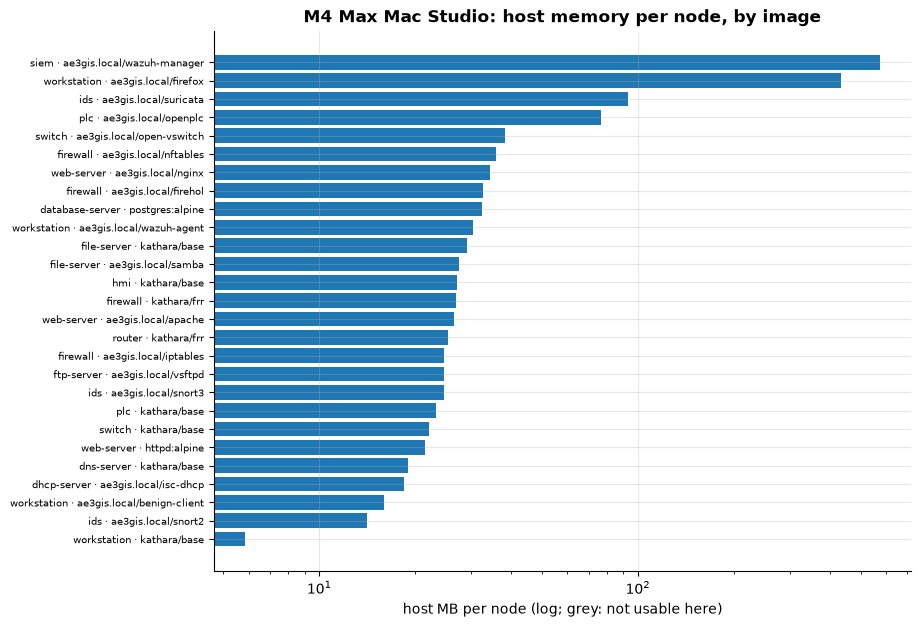

In [6]:
c = rs.census_table(R)
display(c.style.format({"host_mb_per_node": "{:.1f}", "cgroup_mb_per_node": "{:.1f}", "deploy_s": "{:.1f}",
                        "ready_s": "{:.2f}", "disk_mb_per_node": "{:.1f}"}, na_rep="–").hide(axis="index"))
show(plots.census_bars(c, f"{h.name}: host memory per node, by image"))

The census deploys only 5 nodes per image, so for light images the host figure above is mostly the lab's fixed overhead. Each image's **container memory**, measured over every container at the climbs' ceilings (hundreds of nodes), is the sturdier per-image cost:

In [7]:
im = rs.image_memory(R).sort_values(ascending=False).rename("container MB (median over climbs)")
display(im.to_frame().T.style.format("{:.1f}"))

image,ae3gis.local/firefox,ae3gis.local/suricata,ae3gis.local/openplc,postgres:alpine,ae3gis.local/open-vswitch,ae3gis.local/nginx,ae3gis.local/apache,ae3gis.local/samba,httpd:alpine,ae3gis.local/vsftpd,ae3gis.local/firehol,ae3gis.local/nftables,ae3gis.local/iptables,ae3gis.local/snort3,ae3gis.local/snort2,ae3gis.local/benign-client,ae3gis.local/wazuh-agent,kathara/frr,kathara/base,ae3gis.local/isc-dhcp
container MB (median over climbs),397.3,71.0,51.8,30.0,20.2,10.9,8.7,7.9,5.0,3.4,3.1,2.8,2.8,2.7,2.7,2.7,2.1,1.2,1.2,1.2


### Climbs

**Ceiling over all 10 climbs: 1884 ± 545 hosts** (range 1140–2380).

,seed,ceiling,nodes,mem_pct,mb_per_node,deploy_s_per_node,stop,note
climb,,,,,,,,
1,1,1140,1182,49.5,36.9,1.25,memory,broken Docker
2,2,1200,1244,59.5,30.3,1.39,deploy failed,broken Docker
3,3,1140,1182,55.4,29.3,1.20,deploy failed,broken Docker
4,4,2280,2363,74.9,25.0,0.63,deploy failed,
5,5,2350,2435,76.2,25.1,0.59,deploy failed,
6,6,1640,1700,51.2,29.6,0.39,teardown failed,teardown failed
7,7,2380,2465,73.3,21.7,0.64,deploy failed,
8,8,2070,2146,65.2,26.1,0.55,deploy failed,
9,9,2350,2435,80.1,23.2,0.61,deploy failed,


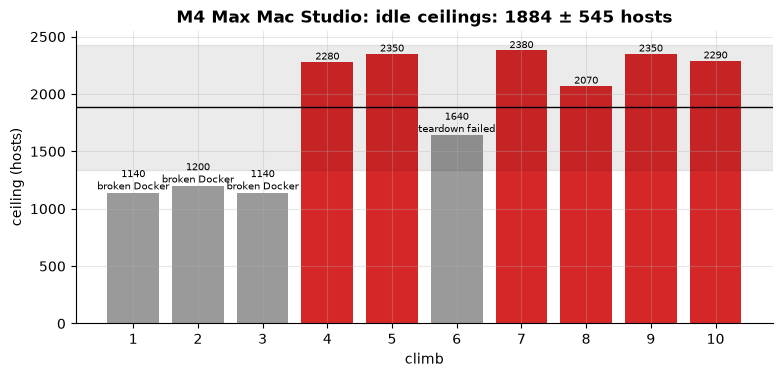

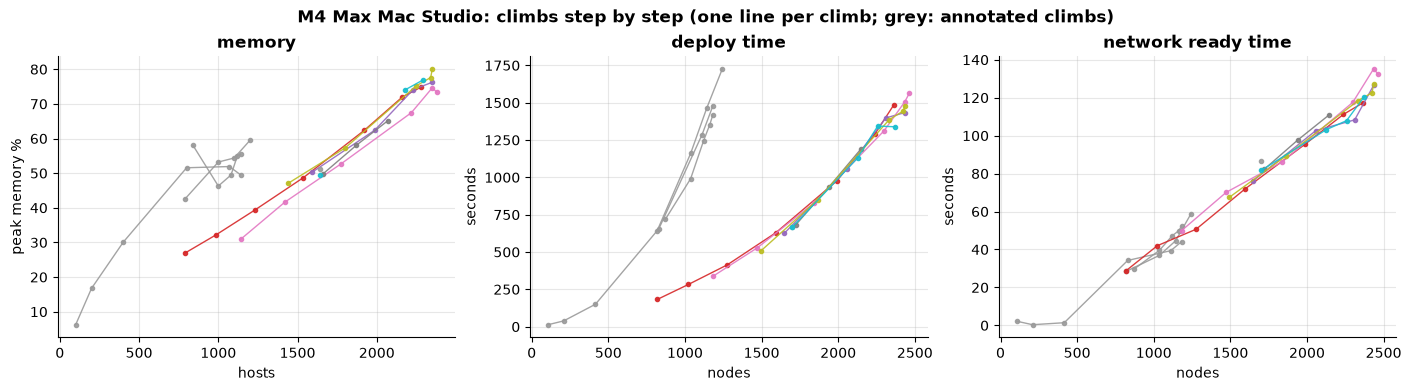

In [8]:
st = rs.ceiling_stats(R)
display(Markdown(f"**Ceiling over all {st['climbs']:.0f} climbs: {st['mean']:.0f} ± {st['std']:.0f} hosts** "
                 f"(range {st['min']:.0f}–{st['max']:.0f})."))
t = rs.climb_table(R).assign(stop=rs.climb_stops(R).values)
display(t[["seed", "ceiling", "nodes", "mem_pct", "mb_per_node", "deploy_s_per_node", "stop", "note"]]
        .style.format({"mem_pct": "{:.1f}", "mb_per_node": "{:.1f}", "deploy_s_per_node": "{:.2f}"}, na_rep="–"))
show(plots.ceilings(R.climbs, h.color, f"{h.name}: idle ceilings"))
show(plots.trajectories(R.steps, R.climbs, f"{h.name}: climbs step by step"))

### What drives the spread between climbs

Each climb draws a different mix. The scatter below sets its ceiling against what one node of that mix costs, from the census. The table lists the images whose share of the mix moves the ceiling most.

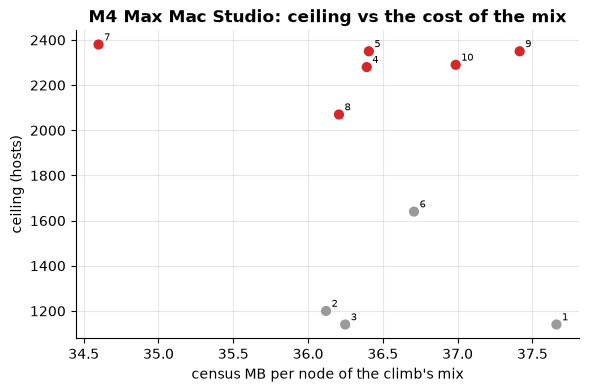

case,corr_with_ceiling,share_min_pct,share_max_pct,count_min,count_max,host_mb_per_node
plc · ae3gis.local/openplc,+0.61,2.800000,4.100000,33,100,76.3
dhcp-server · ae3gis.local/isc-dhcp,+0.59,6.600000,8.100000,79,198,18.4
web-server · httpd:alpine,+0.55,2.300000,3.300000,27,81,21.4


In [9]:
cc = rs.composition_cost(R)
show(plots.ceiling_vs_mix(cc, h.color, f"{h.name}: ceiling vs the cost of the mix"))
display(rs.drivers(R).style.format({"corr_with_ceiling": "{:+.2f}", "host_mb_per_node": "{:.1f}"}).hide(axis="index"))

### Share of each type at the ceiling (%)

In [10]:
display(rs.type_shares(R).T)

,switch,firewall,dns-server,hmi,router,file-server,ftp-server,database-server,web-server,ids,dhcp-server,workstation,plc
mean,10.4,7.8,7.8,7.6,7.6,7.5,7.5,7.5,7.4,7.3,7.3,7.2,7.1
std,0.4,0.7,0.5,0.5,1.0,0.4,0.6,0.7,0.5,0.3,0.5,0.6,0.5


## 2. Traffic limits (`traffic` suite)

100 cells: 5 rates × 5 burst intervals × TCP/UDP × two patterns.
- **clients → servers:** one flow per host, north–south through the routers and core.
- **mesh:** two flows per host, east–west inside a LAN.

For each cell, the search finds the most hosts whose traffic still gets through (≥ 95% delivered, ≤ 1% UDP loss) and where it fails, 50 hosts apart; the comfortable size passes twice. Grid markers:
- `mem`: a host limit (memory, a deploy that failed or took too long), not traffic;
- `tool`: clients not started in time;
- `≥ N`: never failed up to N;
- `…`: still being searched.

In [11]:
display(ts.overview(T).to_frame('').style)

,
cells final,100 of 100
probes (lab sizes measured),137
rounds,18
cell runs,556
cell runs by the fixed driver,0
results dropped (re-check / repair),34
re-check rules applied,–
started,2026-10-11 14:11
last update,2026-10-15 20:04


### Limits: comfortable / fails at (hosts)

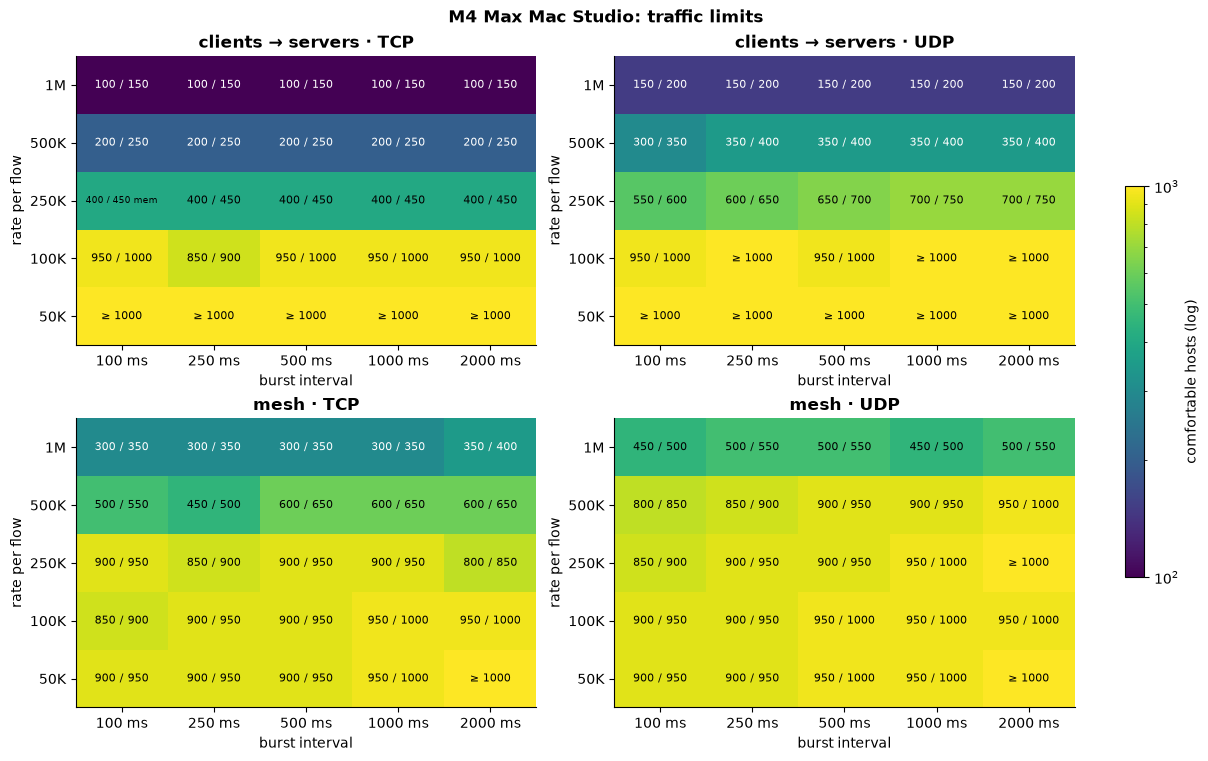

In [12]:
show(plots.limit_heatmaps(T.cells, f"{h.name}: traffic limits"))

### Traffic carried at the comfortable size (Mb/s offered = hosts × rate × flows per host)

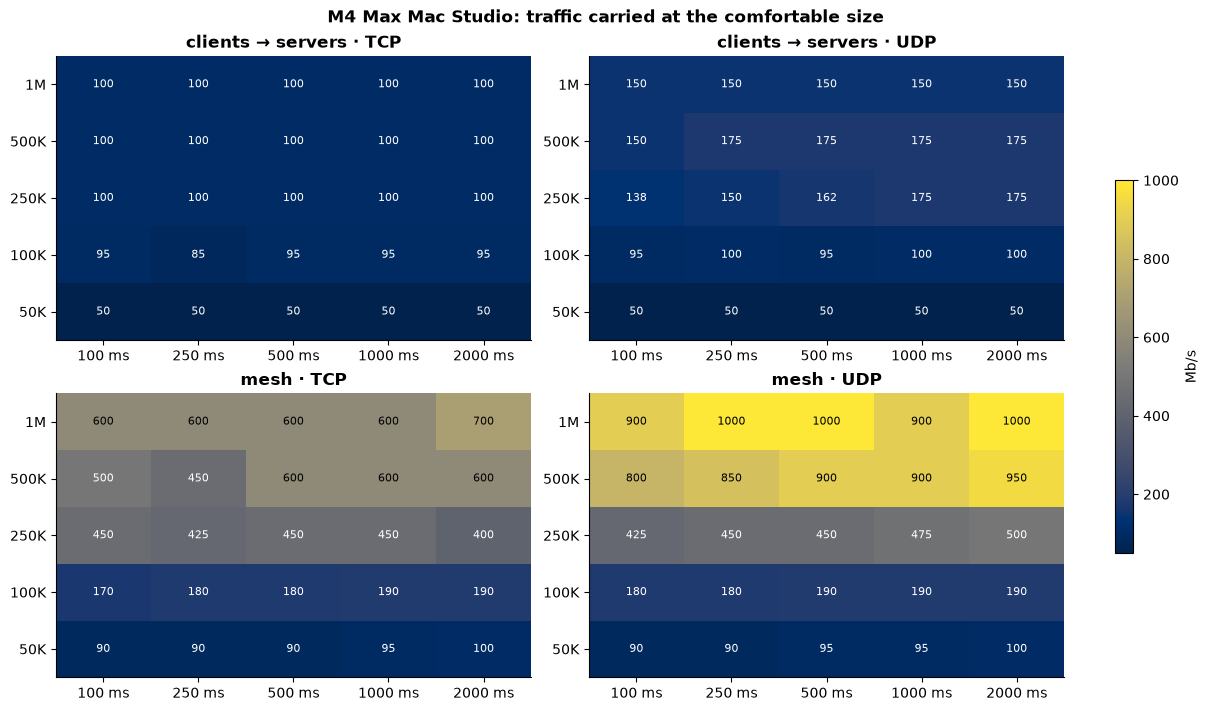

In [13]:
grids = {s: ts.grid(T.cells, s, "carried_mbps") for s in ts.SCENARIO_ORDER}
show(plots.value_heatmaps(grids, f"{h.name}: traffic carried at the comfortable size", unit="Mb/s", cmap="cividis"))

### What the traffic costs

How much of the host's CPU the lab's containers use per 100 Mb/s delivered, by scenario and lab size (passing runs). On one machine it should be roughly flat.

A cost that falls with lab size is the signature of partial load: under the old driver, big labs' clients were still starting during the measured window. Nodes receive each delivered byte several times: once per hop.

bin,0–250,250–450,450–650,650–850,850–1100
scenario,,,,,
cs·tcp,5.50,6.50,–,7.89,6.93
cs·udp,3.36,3.40,4.30,3.93,4.52
mesh·tcp,1.72,1.66,1.62,1.81,1.74
mesh·udp,–,1.05,0.94,0.86,0.97


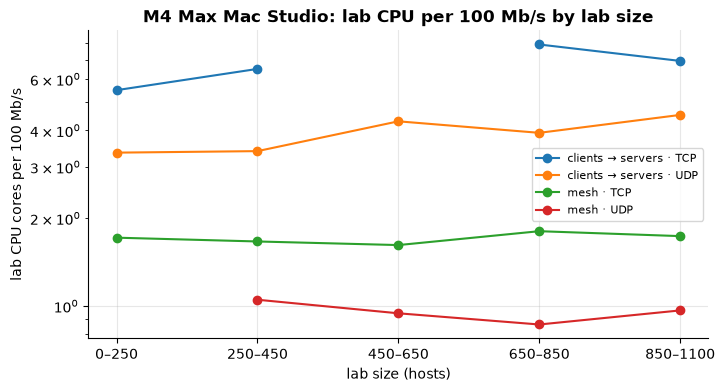

scenario,cs·tcp,cs·udp,mesh·tcp,mesh·udp
node receives per delivered byte,6.2,5.6,1.7,1.1


In [14]:
cost = ts.cost_by_size(T.rows)
display(cost.style.format("{:.2f}", na_rep="–"))
show(plots.cost_lines(cost, f"{h.name}: lab CPU per 100 Mb/s by lab size"))
k = ts.kept(T.rows)
display(k[k["outcome"] == "ok"].groupby("scenario")["rx_per_delivered"].median()
        .rename("node receives per delivered byte").to_frame().T.style.format("{:.1f}"))

### What set each cell's limit

In [15]:
display(ts.reasons(T.cells))
f = ts.at_limit(T, "fails")
if not f.empty:
    display(f.groupby(["scenario", "reason"])[["cpu_pct", "mem_pct", "delivered_ratio", "loss_pct"]]
            .median().style.format({"cpu_pct": "{:.0f}", "mem_pct": "{:.0f}", "delivered_ratio": "{:.0%}",
                                    "loss_pct": "{:.1f}"}, na_rep="–")
            .set_caption("At the size each cell fails at (medians)"))

kind,delivery,deploy failed,loss,never failed (≥)
scenario,,,,
cs·tcp,19,1,0,5
cs·udp,14,0,3,8
mesh·tcp,24,0,0,1
mesh·udp,23,0,0,2


### Latency (TCP) and loss (UDP) at the comfortable size

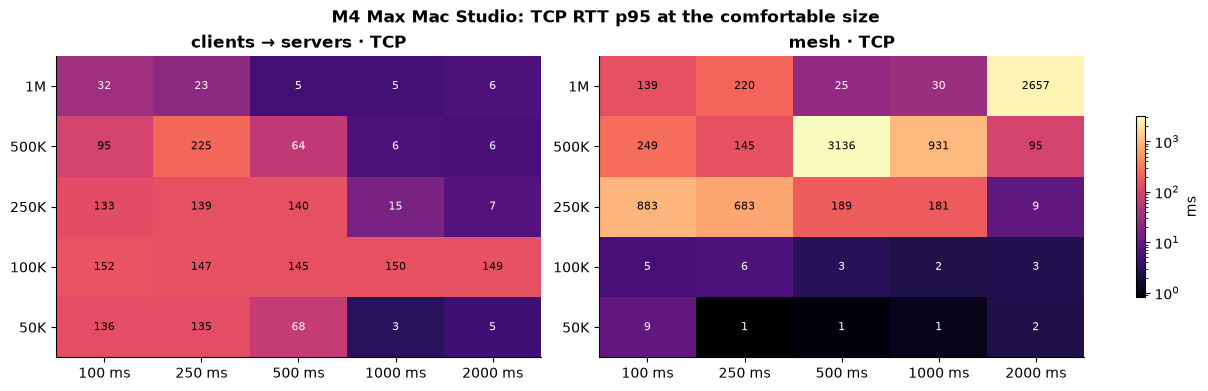

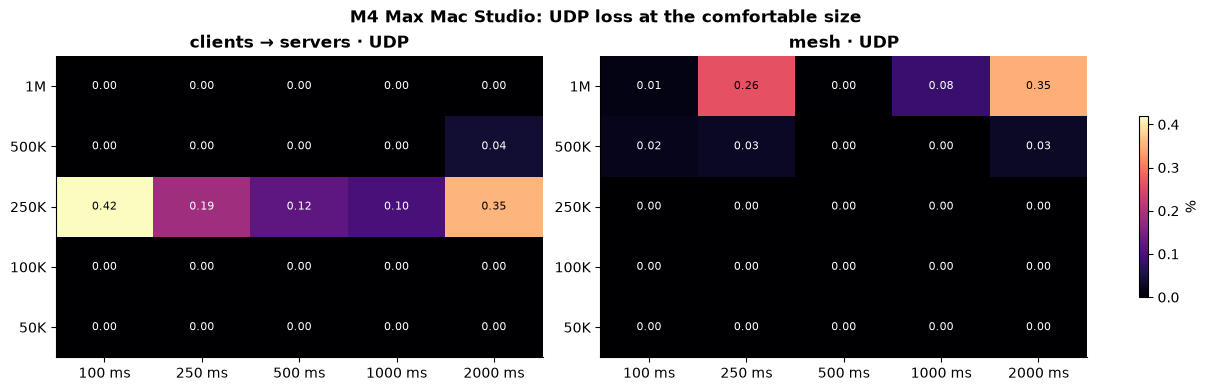

In [16]:
ok = ts.at_limit(T, "comfortable")
if not ok.empty:
    pivot = lambda s, v: ok[ok["scenario"] == s].pivot(index="rate", columns="interval_ms", values=v)
    show(plots.value_heatmaps({s: pivot(s, "rtt_p95_ms") for s in ("cs·tcp", "mesh·tcp")},
                              f"{h.name}: TCP RTT p95 at the comfortable size", unit="ms", log=True))
    show(plots.value_heatmaps({s: pivot(s, "loss_pct") for s in ("cs·udp", "mesh·udp")},
                              f"{h.name}: UDP loss at the comfortable size", fmt="{:.2f}", unit="%"))

### The burst interval's effect

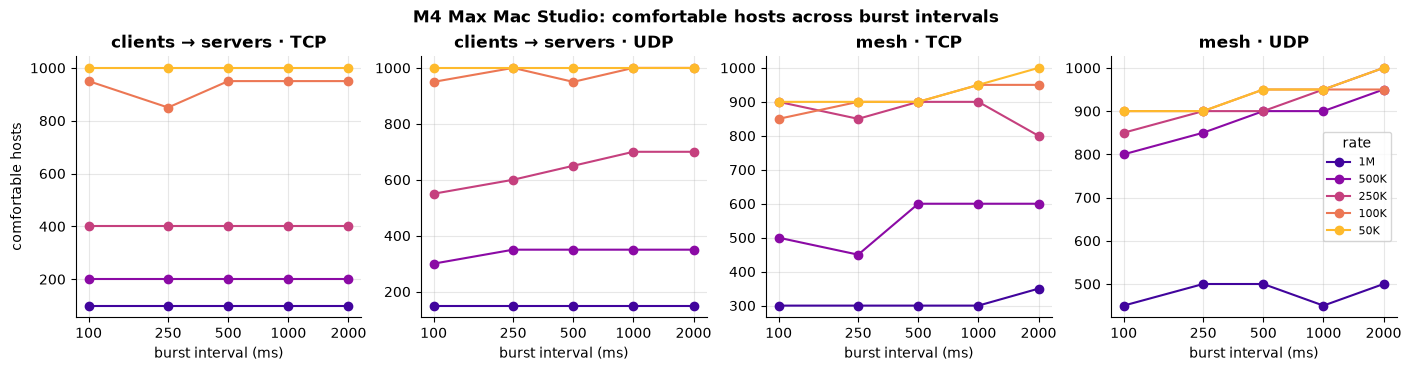

In [17]:
show(plots.interval_lines(T.cells, f"{h.name}: comfortable hosts across burst intervals"))

### What a lab costs to deploy, by size

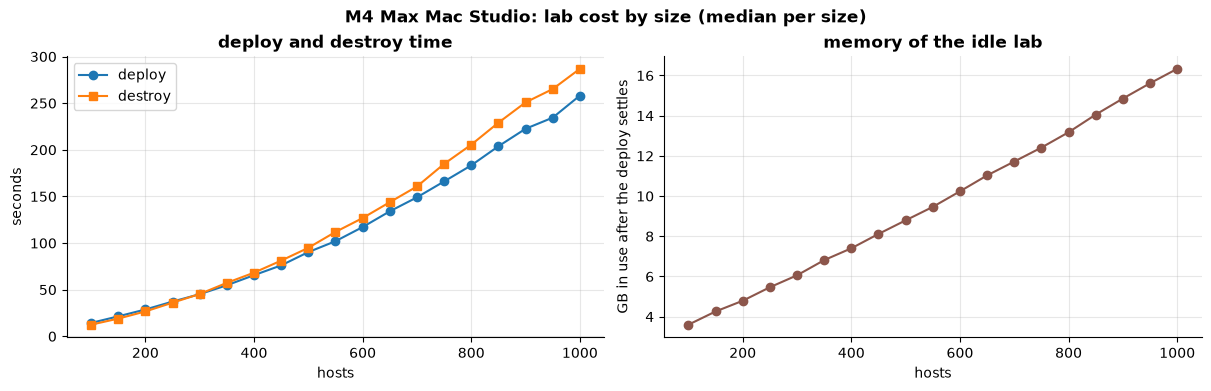

In [18]:
show(plots.deploy_costs(T.deploys, f"{h.name}: lab cost by size (median per size)"))

### How the search went (every counted probe per cell)

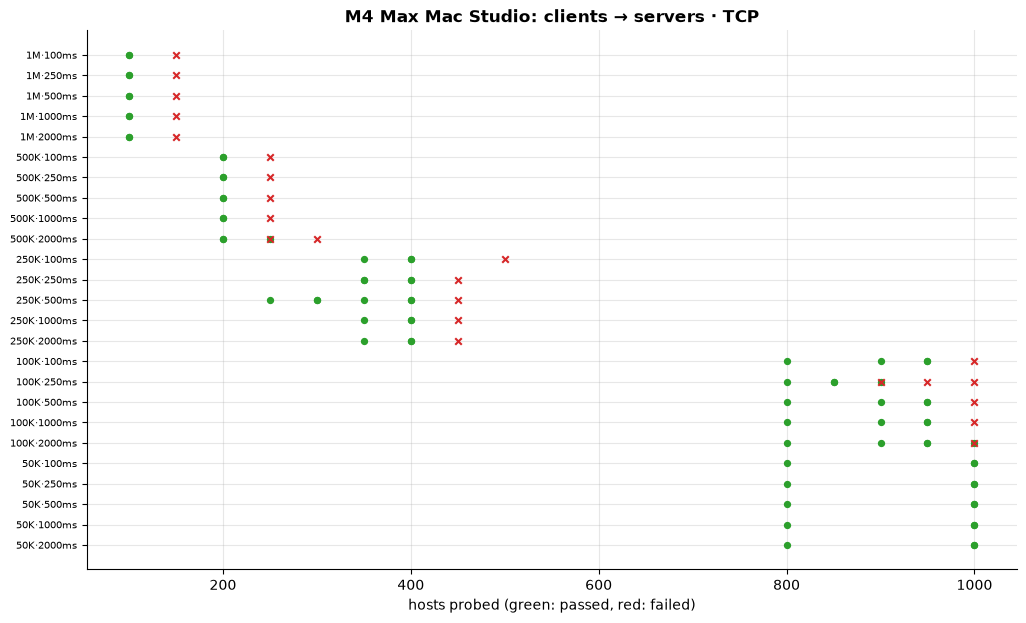

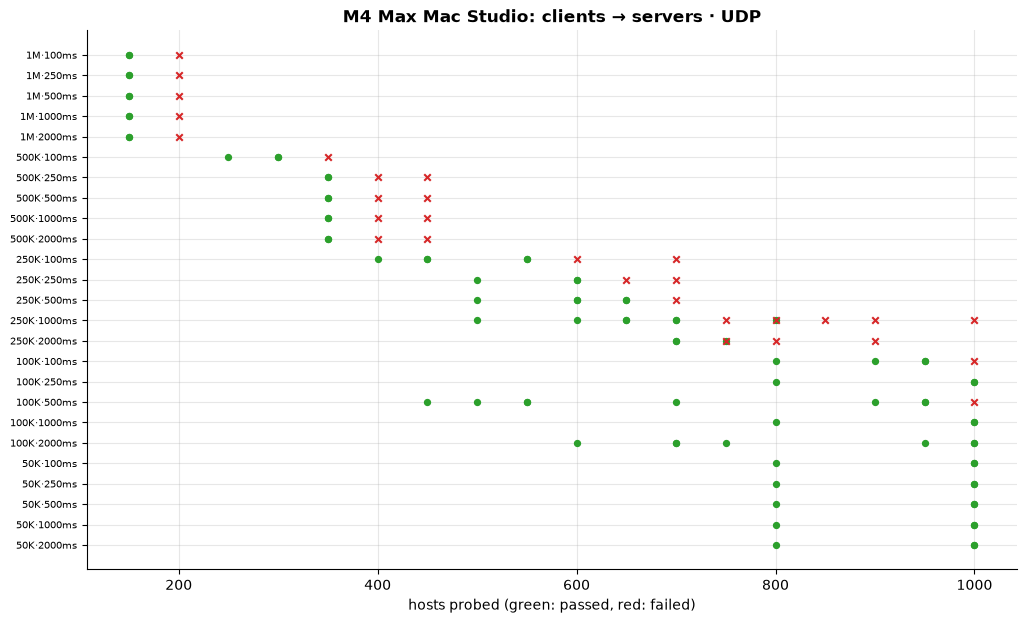

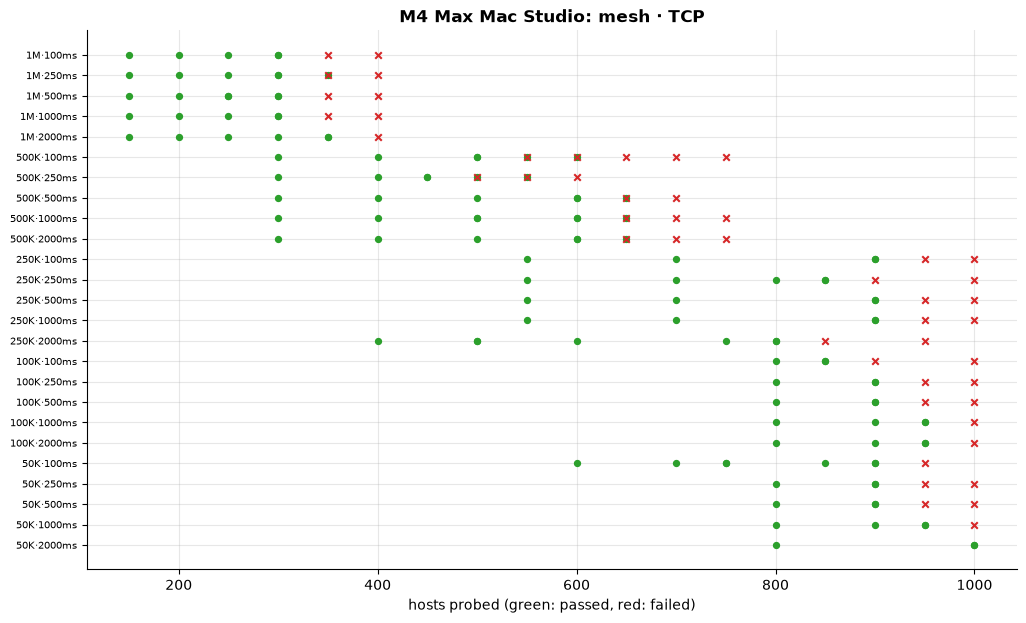

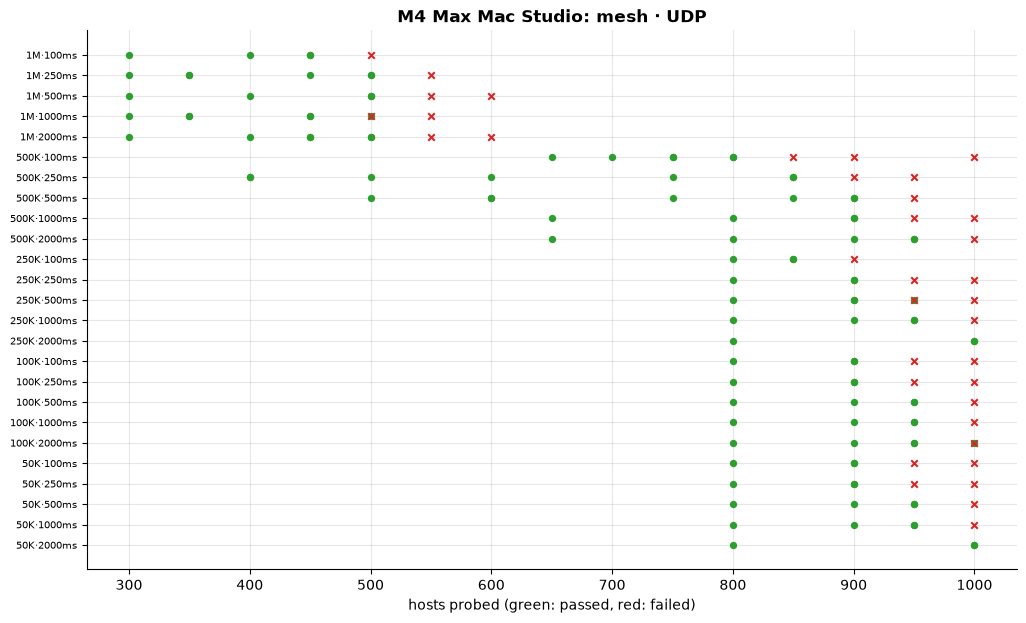

In [19]:
for s in ts.SCENARIO_ORDER:
    show(plots.search_history(ts.search_history(T, s), f"{h.name}: {plots._scenario(s)}"))

## 3. Data quality

Which traffic driver measured each run, and the old driver's symptoms in mesh labs, by lab size:
- **dead flows:** at least 5% of flows delivered nothing;
- **memory stalls:** full PSI.

Under the fixed driver every client starts before the window, so dead flows there are a real overload: clients that couldn't connect.

In [20]:
for pattern in ("mesh", "cs"):
    q = ts.quality_by_size(T.rows, pattern)
    if not q.empty:
        display(q.style.format({"dead_flows_pct": "{:.0f}", "psi_mem_full_median": "{:.1f}",
                                "mem_pct_median": "{:.0f}"}).set_caption(f"{pattern} labs"))
if len(T.dropped):
    display(T.dropped.groupby(["by", "why"]).size().rename("results dropped").to_frame())

results dropped
by     why                               
repair deploy connection                3
       not running                     31